# MiniGPT From Scratch — AI Engineering Assignment
**Purpose:** Train a small causal Transformer on Tiny Shakespeare without using a pretrained language model.

> Run cells from top to bottom in Google Colab. Start with Runtime → Change runtime type → T4 GPU if available. Keep a copy of this notebook in your team's Google Drive/GitHub.

## Team division suggestion
- **Member 1:** tokenizer, dataset, attention, causal-mask tests, hand calculation.
- **Member 2:** Transformer model, training, loss curves, generation.
- **Member 3 (if applicable):** ablations, visualizations, README/report/demo.
Everyone should understand the complete model.

## Important
This notebook implements the architecture directly with PyTorch layers and tensor operations. It does not load a pretrained GPT checkpoint. Record actual results from your own run; do not report placeholder measurements.

## 1. Setup and reproducibility

In [1]:
import os, math, time, random, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


## 2. Download and inspect Tiny Shakespeare

In [2]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
data_path = Path("/content/tinyshakespeare.txt")
if not data_path.exists():
    urllib.request.urlretrieve(DATA_URL, data_path)
text = data_path.read_text(encoding="utf-8")
print("Characters:", len(text))
print(text[:500])

Characters: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 3. Character-level tokenizer and train/validation split
Each unique character receives a deterministic integer ID. This simple tokenizer is allowed by the assignment. The target sequence is shifted one character to the right during training.

In [3]:
chars = sorted(list(set(text)))
stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for ch,i in stoi.items()}
vocab_size = len(chars)

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

all_ids = torch.tensor(encode(text), dtype=torch.long)
split_idx = int(0.9 * len(all_ids))
train_ids = all_ids[:split_idx]
val_ids = all_ids[split_idx:]
print("Vocabulary size:", vocab_size)
print("Train tokens:", len(train_ids), "Validation tokens:", len(val_ids))

Vocabulary size: 65
Train tokens: 1003854 Validation tokens: 111540


## 4. Batch creation: next-token prediction

In [4]:
context_length = 128
batch_size = 64

def get_batch(split, batch_size=batch_size, block_size=context_length):
    source = train_ids if split == "train" else val_ids
    ix = torch.randint(len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[i:i+block_size] for i in ix])
    y = torch.stack([source[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input shape:", tuple(xb.shape), "Target shape:", tuple(yb.shape))
print("Example input:", repr(decode(xb[0][:60].tolist())))
print("Example target:", repr(decode(yb[0][:60].tolist())))

Input shape: (64, 128) Target shape: (64, 128)
Example input: ' passage.\n\nSecond Watchman:\nAy, wherefore else guard we his '
Example target: 'passage.\n\nSecond Watchman:\nAy, wherefore else guard we his r'


## 5. Self-attention from scratch
For each token representation, linear projections create queries (Q), keys (K), and values (V). Scores are scaled by \(\sqrt{d_k}\), future positions are masked, softmax converts scores to weights, and the weights combine V.

In [5]:
class SelfAttentionHead(nn.Module):
    def __init__(self, d_model, head_dim, context_length, dropout=0.1):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_length, context_length)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)       # (B,T,head_dim)
        q = self.query(x)     # (B,T,head_dim)
        v = self.value(x)     # (B,T,head_dim)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.size(-1))  # (B,T,T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        out = weights @ v
        return out, weights

### 5a. Unit checks for causal masking

In [6]:
torch.manual_seed(SEED)
test_head = SelfAttentionHead(d_model=8, head_dim=4, context_length=8, dropout=0.0).to(device)
test_x = torch.randn(2, 5, 8, device=device)
test_out, test_weights = test_head(test_x)
assert test_out.shape == (2, 5, 4)
assert test_weights.shape == (2, 5, 5)
# Every entry strictly above the diagonal must be zero after softmax.
future_weights = torch.triu(test_weights, diagonal=1)
assert torch.allclose(future_weights, torch.zeros_like(future_weights), atol=1e-7)
print("PASS: attention shapes and future-token masking")
print("Output shape:", tuple(test_out.shape), "Attention shape:", tuple(test_weights.shape))

PASS: attention shapes and future-token masking
Output shape: (2, 5, 4) Attention shape: (2, 5, 5)


## 6. Multi-head attention and sinusoidal positional encoding
Each head attends separately. The outputs are concatenated and projected back to `d_model`. Positional encoding adds information about token order.

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_length, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        head_dim = d_model // n_heads
        self.heads = nn.ModuleList([
            SelfAttentionHead(d_model, head_dim, context_length, dropout)
            for _ in range(n_heads)
        ])
        self.proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        results = [head(x) for head in self.heads]
        out = torch.cat([r[0] for r in results], dim=-1)
        out = self.dropout(self.proj(out))
        if return_attention:
            return out, [r[1] for r in results]
        return out

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) *
                             (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

### 6a. Shape trace

In [8]:
shape_test = torch.randn(2, 12, 32, device=device)
mha_test = MultiHeadAttention(d_model=32, n_heads=4, context_length=16).to(device)
mha_out, attn_maps = mha_test(shape_test, return_attention=True)
print("Input:", tuple(shape_test.shape))
print("Each head attention map:", tuple(attn_maps[0].shape))
print("Concatenated/projected output:", tuple(mha_out.shape))
assert mha_out.shape == shape_test.shape

Input: (2, 12, 32)
Each head attention map: (2, 12, 12)
Concatenated/projected output: (2, 12, 32)


## 7. Transformer block and MiniGPT
A block uses pre-layer normalization, causal multi-head attention, residual connections, and a feed-forward MLP. The language-model head maps hidden states to vocabulary logits.

In [9]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, context_length, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, context_length, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.GELU(),
            nn.Linear(4*d_model, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=3,
                 context_length=128, dropout=0.1):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position = SinusoidalPositionalEncoding(d_model, context_length)
        self.blocks = nn.Sequential(*[
            TransformerBlock(d_model, n_heads, context_length, dropout)
            for _ in range(n_layers)
        ])
        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.context_length:
            idx = idx[:, -self.context_length:]
            T = idx.size(1)
            if targets is not None:
                targets = targets[:, -T:]
        x = self.token_embedding(idx)
        x = self.position(x)
        x = self.blocks(x)
        logits = self.lm_head(self.final_ln(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=200, temperature=0.8, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_length:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < values[:, [-1]]] = -float("inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        return idx

## 8. Instantiate model and run shape/parameter checks

In [10]:
config = {
    "context_length": 128,
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 3,
    "dropout": 0.1,
    "learning_rate": 3e-4,
    "batch_size": 64,
    "max_steps": 1200,
    "eval_interval": 100,
    "eval_batches": 20
}
model = MiniGPT(vocab_size, d_model=config["d_model"], n_heads=config["n_heads"],
                n_layers=config["n_layers"], context_length=config["context_length"],
                dropout=config["dropout"]).to(device)
num_params = sum(p.numel() for p in model.parameters())
print("Parameter count:", f"{num_params:,}")
logits, loss = model(xb, yb)
print("Logits shape:", tuple(logits.shape), "Initial loss:", round(loss.item(), 4))
assert logits.shape == (batch_size, context_length, vocab_size)

Parameter count: 610,625
Logits shape: (64, 128, 65) Initial loss: 4.3678


## 9. Training loop with train/validation loss
Run the baseline first. If Colab disconnects or training is too slow, reduce `max_steps` and document the actual value used. A falling training loss is expected, but validation loss and generated samples must also be inspected.

In [11]:
@torch.no_grad()
def estimate_loss(model, eval_batches=20):
    model.eval()
    results = {}
    for split in ("train", "val"):
        losses = []
        for _ in range(eval_batches):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())
        results[split] = float(np.mean(losses))
    model.train()
    return results

optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"])
train_history, val_history, step_history = [], [], []
start_time = time.time()
model.train()

for step in range(config["max_steps"] + 1):
    if step % config["eval_interval"] == 0:
        metrics = estimate_loss(model, config["eval_batches"])
        step_history.append(step)
        train_history.append(metrics["train"])
        val_history.append(metrics["val"])
        elapsed = time.time() - start_time
        print(f"step {step:4d} | train {metrics['train']:.4f} | val {metrics['val']:.4f} | elapsed {elapsed/60:.1f} min")
    if step == config["max_steps"]:
        break
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

training_seconds = time.time() - start_time
print(f"Training time: {training_seconds/60:.2f} minutes")

step    0 | train 4.3647 | val 4.3429 | elapsed 0.0 min
step  100 | train 2.5624 | val 2.5684 | elapsed 0.1 min
step  200 | train 2.4471 | val 2.4519 | elapsed 0.1 min
step  300 | train 2.3332 | val 2.3484 | elapsed 0.2 min
step  400 | train 2.2333 | val 2.2537 | elapsed 0.2 min
step  500 | train 2.1592 | val 2.1935 | elapsed 0.3 min
step  600 | train 2.0921 | val 2.1333 | elapsed 0.3 min
step  700 | train 2.0271 | val 2.0815 | elapsed 0.4 min
step  800 | train 1.9792 | val 2.0409 | elapsed 0.4 min
step  900 | train 1.9232 | val 2.0027 | elapsed 0.5 min
step 1000 | train 1.8791 | val 1.9803 | elapsed 0.5 min
step 1100 | train 1.8466 | val 1.9546 | elapsed 0.6 min
step 1200 | train 1.8035 | val 1.9351 | elapsed 0.6 min
Training time: 0.61 minutes


### 9a. Plot the loss curve

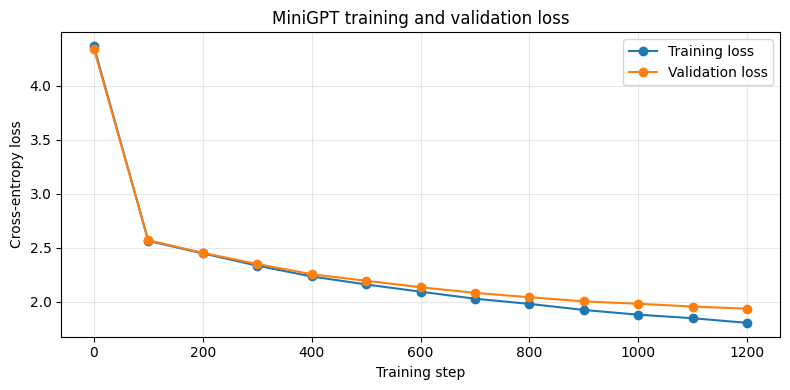

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(step_history, train_history, marker="o", label="Training loss")
plt.plot(step_history, val_history, marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("MiniGPT training and validation loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/content/loss_curve.png", dpi=160)
plt.show()

## 10. Generate text and save a checkpoint

In [13]:
prompt = "ROMEO:"
prompt_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
generated_ids = model.generate(prompt_ids, max_new_tokens=400, temperature=0.8, top_k=40)
sample = decode(generated_ids[0].tolist())
print(sample)

os.makedirs("/content/checkpoints", exist_ok=True)
checkpoint_path = "/content/checkpoints/minigpt.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "config": config,
    "vocab_size": vocab_size,
    "chars": chars,
    "parameter_count": num_params
}, checkpoint_path)
print("Saved checkpoint:", checkpoint_path)
with open("/content/generated_sample.txt", "w", encoding="utf-8") as f:
    f.write(sample)

ROMEO:
Should sto by loed, in and I the to me to beather
I but my the yourse frecied, the he good.

FRIHAR S:
Not not will stich on thimers hearth from in thers
O bearat your stake and that the urpon bon others
What dith wiich hesert them.

CARDWICK:

How it thou mastterer?

And Has blood!

ISABESLLABED:
If the breied, it now me ming for I past thee set
Trepheer withe fure to neach day dister thou your 
Saved checkpoint: /content/checkpoints/minigpt.pt


## 11. Visualize positional encoding and attention
These figures can be used as report evidence. Include notebook/terminal context in screenshots so they clearly come from your implementation.

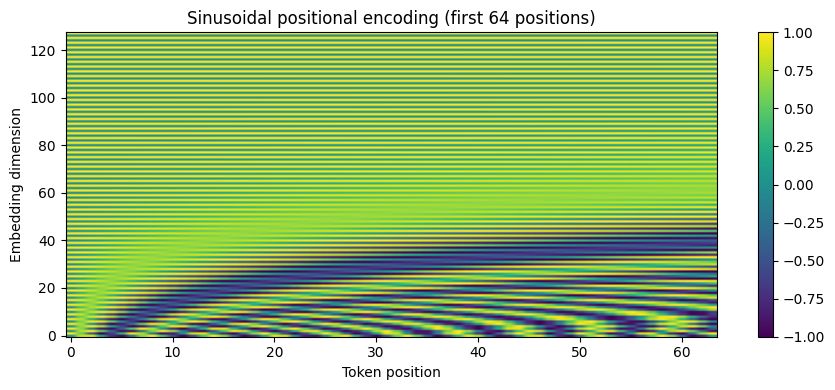

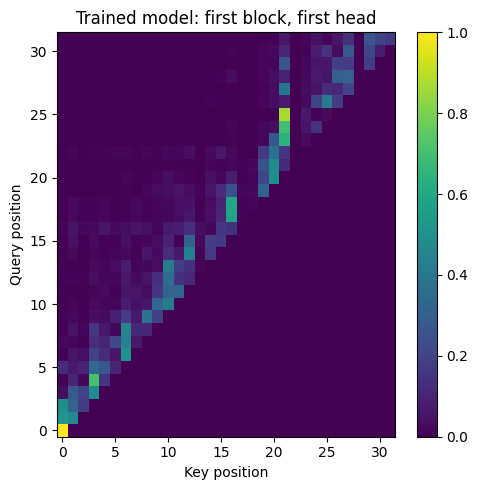

In [14]:
pe = model.position.pe[0].detach().cpu().numpy()
plt.figure(figsize=(9, 4))
plt.imshow(pe[:64].T, aspect="auto", origin="lower")
plt.xlabel("Token position")
plt.ylabel("Embedding dimension")
plt.title("Sinusoidal positional encoding (first 64 positions)")
plt.colorbar()
plt.tight_layout()
plt.savefig("/content/positional_encoding.png", dpi=160)
plt.show()

# Inspect attention weights in the first head of the first block.
model.eval()
sample_x, _ = get_batch("val", batch_size=1, block_size=32)
with torch.no_grad():
    embedded = model.position(model.token_embedding(sample_x))
    _, attention_maps = model.blocks[0].attn(model.blocks[0].ln1(embedded), return_attention=True)
attention = attention_maps[0][0].detach().cpu().numpy()
plt.figure(figsize=(5, 5))
plt.imshow(attention, origin="lower", aspect="auto")
plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Trained model: first block, first head")
plt.colorbar()
plt.tight_layout()
plt.savefig("/content/attention_heatmap.png", dpi=160)
plt.show()

## 12. Controlled ablations
The assignment asks for at least three experiments. This cell compares depth, number of heads, and context length, changing one factor at a time. To save time, each run is intentionally short; for your report, clearly state the number of steps and treat the measurements as preliminary. Use the same dataset split and seed. Do not compare runs with different step counts as if they were perfectly controlled.

In [15]:
def run_short_experiment(label, d_model=64, n_heads=4, n_layers=2, context_length=64,
                         steps=150, batch=32, lr=3e-4):
    # Re-seed each run for reproducibility; short runs are indicative, not definitive.
    torch.manual_seed(SEED)
    exp_model = MiniGPT(vocab_size, d_model=d_model, n_heads=n_heads,
                        n_layers=n_layers, context_length=context_length, dropout=0.0).to(device)
    opt = torch.optim.AdamW(exp_model.parameters(), lr=lr)
    t0 = time.time()
    for _ in range(steps):
        x, y = get_batch("train", batch_size=batch, block_size=context_length)
        _, l = exp_model(x, y)
        opt.zero_grad(set_to_none=True)
        l.backward()
        torch.nn.utils.clip_grad_norm_(exp_model.parameters(), 1.0)
        opt.step()
    elapsed = time.time() - t0
    exp_model.eval()
    vals = []
    with torch.no_grad():
        for _ in range(20):
            x, y = get_batch("val", batch_size=batch, block_size=context_length)
            _, l = exp_model(x, y)
            vals.append(l.item())
    count = sum(p.numel() for p in exp_model.parameters())
    return {"experiment":label, "d_model":d_model, "heads":n_heads, "layers":n_layers,
            "context":context_length, "steps":steps, "parameters":count,
            "validation_loss":float(np.mean(vals)), "seconds":round(elapsed, 1)}

# Baseline and one-factor changes; adjust steps downward if runtime is limited.
ablation_results = []
ablation_results.append(run_short_experiment("depth_2", n_layers=2))
ablation_results.append(run_short_experiment("depth_3", n_layers=3))
ablation_results.append(run_short_experiment("heads_2", n_heads=2))
ablation_results.append(run_short_experiment("context_128", context_length=128))
import pandas as pd
ablation_df = pd.DataFrame(ablation_results)
display(ablation_df)
ablation_df.to_csv("/content/ablation_results.csv", index=False)

,experiment,d_model,heads,layers,context,steps,parameters,validation_loss,seconds
0,depth_2,64,4,2,64,150,108097,2.777573,1.9
1,depth_3,64,4,3,64,150,157889,2.709275,2.6
2,heads_2,64,2,2,64,150,108097,2.773292,1.3
3,context_128,64,4,2,128,150,108097,2.760327,2.4


## 13. Hand-calculated attention example (report artifact)
Use the matrices below as a transparent numeric example. These are illustrative hand calculations, separate from learned model weights. Compute each step in your report and compare the numbers with the printed values.

We use three tokens and \(d_k=d_v=2\). Since Q=K, the scores are easy to calculate.

In [16]:
Q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
K = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
V = torch.tensor([[1., 0.], [0., 2.], [3., 1.]])
raw_scores = Q @ K.T
scaled_scores = raw_scores / math.sqrt(2)
weights_unmasked = F.softmax(scaled_scores, dim=-1)
output_unmasked = weights_unmasked @ V
causal = torch.tril(torch.ones(3,3))
masked_scores = scaled_scores.masked_fill(causal == 0, float("-inf"))
weights_masked = F.softmax(masked_scores, dim=-1)
output_masked = weights_masked @ V

print("QK^T =\n", raw_scores)
print("Scaled scores =\n", scaled_scores)
print("Unmasked softmax weights =\n", weights_unmasked)
print("Unmasked output =\n", output_unmasked)
print("Causal masked scores (-inf means blocked) =\n", masked_scores)
print("Masked weights =\n", weights_masked)
print("Masked output =\n", output_masked)

QK^T =
 tensor([[1., 0., 1.],
        [0., 1., 1.],
        [1., 1., 2.]])
Scaled scores =
 tensor([[0.7071, 0.0000, 0.7071],
        [0.0000, 0.7071, 0.7071],
        [0.7071, 0.7071, 1.4142]])
Unmasked softmax weights =
 tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]])
Unmasked output =
 tensor([[1.6044, 0.7967],
        [1.4011, 1.2033],
        [1.7587, 1.0000]])
Causal masked scores (-inf means blocked) =
 tensor([[0.7071,   -inf,   -inf],
        [0.0000, 0.7071,   -inf],
        [0.7071, 0.7071, 1.4142]])
Masked weights =
 tensor([[1.0000, 0.0000, 0.0000],
        [0.3302, 0.6698, 0.0000],
        [0.2483, 0.2483, 0.5035]])
Masked output =
 tensor([[1.0000, 0.0000],
        [0.3302, 1.3395],
        [1.7587, 1.0000]])


### Explanation to include in the report
- **QKᵀ:** measures compatibility between each query token and each key token.
- **Scaling:** dividing by √dₖ keeps dot products from becoming excessively large as dimensions grow.
- **Softmax:** turns each row into attention weights that sum to 1.
- **Weighted values:** attention uses those weights to combine information from V.
- **Causal mask:** positions cannot attend to future tokens. Token 1 can see only token 1; token 2 can see tokens 1–2; token 3 can see tokens 1–3. This prevents information leakage during next-token prediction.

## 14. BERT MLM vs GPT causal LM
| Property | BERT-style masked language modeling | GPT-style causal language modeling |
|---|---|---|
| Attention | Bidirectional context is allowed | Future positions are blocked |
| Training target | Predict selected masked tokens | Predict the next token |
| Typical use | Understanding/representation learning | Autoregressive text generation |
| Mask | No causal triangular restriction for ordinary encoder attention | Lower-triangular causal mask |

This assignment requires explaining the difference; it does not require implementing a full BERT model.

## 15. Export artifacts
Download these from Colab's Files pane or copy them to Google Drive. Do not commit large files unless your instructor asks. A checkpoint stored only in the temporary Colab filesystem will disappear when the runtime resets.

In [17]:
print("Artifacts:")
for p in ["/content/loss_curve.png", "/content/positional_encoding.png",
          "/content/attention_heatmap.png", "/content/ablation_results.csv",
          "/content/generated_sample.txt", "/content/checkpoints/minigpt.pt"]:
    print(p, "exists:", os.path.exists(p))

Artifacts:
/content/loss_curve.png exists: True
/content/positional_encoding.png exists: True
/content/attention_heatmap.png exists: True
/content/ablation_results.csv exists: True
/content/generated_sample.txt exists: True
/content/checkpoints/minigpt.pt exists: True


## Before submission checklist
- [ ] Restart runtime and run all notebook cells from top to bottom.
- [ ] Save notebook to Drive and upload it to the team's Git repository.
- [ ] Save the trained checkpoint somewhere persistent and document how to load it.
- [ ] Capture real screenshots: hand calculation, causal mask, multi-head shapes, positional encoding, parameter count, loss curve, attention map, generated samples, ablation table, inference.
- [ ] Run at least three fixed prompts and preserve the actual outputs.
- [ ] Record the actual configuration, hardware, training duration, losses, and limitations.
- [ ] Add README instructions for setup, training, and inference.
- [ ] For the required API/deployment, package a small FastAPI endpoint that loads this checkpoint; test locally before deploying.
- [ ] Cite any external references or code you adapt.